# 06｜IMDB GloVe 遷移學習（選做）

**研究問題 RQ6：GloVe 預訓練 100 維詞向量是否改善單層 GRU 的情緒分類？**

| Run | Embedding 初始化 | Embedding 是否可訓練 |
|---|---|---|
| DL-03-s42（沿用） | 隨機 | Yes |
| TL-01-s42（新） | GloVe 6B / 100d | No（Frozen） |
| TL-02-s42（新） | GloVe 6B / 100d | Yes（Fine-tuning） |

共用 dedup_v1.1（Train 19,823／Validation 4,956）、TextVectorization 詞彙 12,000、長度 160、GRU(64)、batch 128、Adam(0.001)、10 Epoch、seed 42。無 Dropout、無 EarlyStopping。

本補充實驗在正式 Gate E 之後執行，**只作探索性 Validation 比較**；不重新評估 Test，不修改既有 14 組模型或 Notebook 07。


In [1]:
from pathlib import Path
import sys,json,yaml,numpy as np,pandas as pd
from IPython.display import display,Image
ROOT=Path('/workspace/imdb_matrix_experiment/variants/dedup_v1_1')
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.common import file_hash
OPT=ROOT/'optional_glove'
cfg=yaml.safe_load((OPT/'experiment.yaml').read_text(encoding='utf8'))
coverage=json.loads((OPT/'results/glove_coverage.json').read_text())
source=json.loads((OPT/'results/glove_source_manifest.json').read_text())
frozen=json.loads((OPT/'results/FROZEN_OFFICIAL_GATE_E_BEFORE_OPTIONAL.json').read_text())
assert cfg['version']=='optional-glove-v1.0'
assert cfg['comparison']['official_Test_evaluation']=='prohibited'
print('Data:',cfg['dataset'],'Existing baseline:',cfg['baseline_run'])
print('GloVe original sha256:',source['glove_binary_sha256'])


Data: dedup_v1.1 Existing baseline: DL-03-s42
GloVe original sha256: 4e29827d144c2097654433b1c4be41ce320949f0792ab820991a68fa3e34d494


## 1. GloVe 來源、授權與詞彙映射

採 Wikipedia 2014 + Gigaword 5、6B tokens、400k words、uncased、100d 的預訓練詞向量。官方研究網站：https://nlp.stanford.edu/projects/glove/；本次 100d 壓縮檔使用 Zenodo 鏡像，記錄 SHA256；預訓練向量依 ODC PDDL 1.0 提供。

只對既有 Train 擬合的 Keras vocabulary 精確匹配 GloVe 詞彙，不從 Validation 或 Test 重建詞彙。


In [2]:
vocab=(ROOT/'artifacts/vectorizers/keras_vocabulary_12000.txt').read_text().splitlines()
matrix=np.load(ROOT/source['aligned_matrix_path'],allow_pickle=False)
matched=np.load(ROOT/source['aligned_mask_path'],allow_pickle=False)
assert len(vocab)==len(matrix)==len(matched)==12000
assert vocab[:2]==['','[UNK]'] and matrix.shape==(12000,100)
assert (matrix[0]==0).all() and not matched[0] and not matched[1]
assert file_hash(ROOT/source['aligned_matrix_path'])==source['aligned_matrix_sha256']
display(pd.DataFrame([
  {'Metric':'Vocabulary excluding PAD/UNK','Value':coverage['eligible_vocab_excluding_PAD_UNK']},
  {'Metric':'GloVe exact matched vocabulary','Value':coverage['exact_matching_vocab']},
  {'Metric':'Vocabulary matching %','Value':round(100*coverage['vocab_exact_match_fraction'],2)},
  {'Metric':'Train known-token weighted coverage %','Value':round(100*coverage['train_coverage_excluding_UNK'],2)},
  {'Metric':'Train UNK token count','Value':coverage['train_nonpad_unk_occurrences']}
]))
print('PAD index 0 => zero vector; UNK 1 and other missing tokens => seeded Gaussian N(0,0.05)')


,Metric,Value
0,Vocabulary excluding PAD/UNK,11998.00
1,GloVe exact matched vocabulary,8637.00
2,Vocabulary matching %,71.99
3,Train known-token weighted coverage %,90.95
4,Train UNK token count,289141.00


PAD index 0 => zero vector; UNK 1 and other missing tokens => seeded Gaussian N(0,0.05)


## 2. 模型架構與可訓練參數量

模型共用 Embedding(12000,100,mask_zero=True) → GRU(64) → Dense(1,sigmoid)；兩種 GloVe 僅改 Embedding.trainable。以下只建構未訓練範例，不訓練或推論 Test。


In [3]:
from tools.optional_glove_train import build
import tensorflow as tf
for rid in cfg['new_runs']:
    tf.keras.utils.set_random_seed(42)
    m=build(cfg,matrix,cfg['conditions'][rid]['embedding_trainable'])
    print(rid,'Embedding trainable',m.get_layer('embedding').trainable,
          'trainable params',sum(np.prod(w.shape) for w in m.trainable_weights),
          'model total params',m.count_params())
    del m
    tf.keras.backend.clear_session()


TL-01-s42 Embedding trainable False trainable params 31937 model total params 1231937
TL-02-s42 Embedding trainable True trainable params 1231937 model total params 1231937


2026-11-05 05:55:43.005873: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


## 3. 實際訓練後的 Validation 成績

讀取兩個新訓練模型的成品，以及原始 DL-03 記錄。不會重新訓練原 DL-03。


In [4]:
base=pd.read_csv(ROOT/'results/runs.csv').set_index('run_id').loc['DL-03-s42']
rows=[dict(run_id='DL-03-s42',condition='Random Embedding',
           val_accuracy=base.val_accuracy,val_precision=base.val_precision,
           val_recall=base.val_recall,val_f1=base.val_f1,
           trainable_params=int(base.trainable_params),
           epochs=int(base.epochs_completed),train_time_sec=base.train_time_sec)]
for rid in cfg['new_runs']:
    r=json.loads((OPT/f'results/{rid}.json').read_text())
    assert r['test_evaluations']==0 and file_hash(ROOT/r['model_path'])==r['model_sha256']
    rows.append(dict(run_id=rid,condition=r['condition'],
         val_accuracy=r['val_accuracy'],val_precision=r['val_precision'],
         val_recall=r['val_recall'],val_f1=r['val_f1'],
         trainable_params=r['trainable_params'],epochs=r['epochs_completed'],
         train_time_sec=r['train_time_sec']))
summary=pd.DataFrame(rows)
display(summary.round(4))


,run_id,condition,val_accuracy,val_precision,val_recall,val_f1,trainable_params,epochs,train_time_sec
0,DL-03-s42,Random Embedding,0.8099,0.8125,0.8080,0.8102,1231937,10,12.2460
1,TL-01-s42,GloVe_100d_Frozen,0.8128,0.8632,0.7453,0.7999,31937,10,23.0034
2,TL-02-s42,GloVe_100d_FineTuning,0.8198,0.8885,0.7332,0.8034,1231937,10,23.1748


## 4. 完整 10 Epoch Train/Validation Loss 與 Confusion Matrix

三組共同的訓練預算，不使用 EarlyStopping；依歷史曲線檢查收斂與過度擬合。


TL-01-s42 Loss curve and Validation confusion matrix


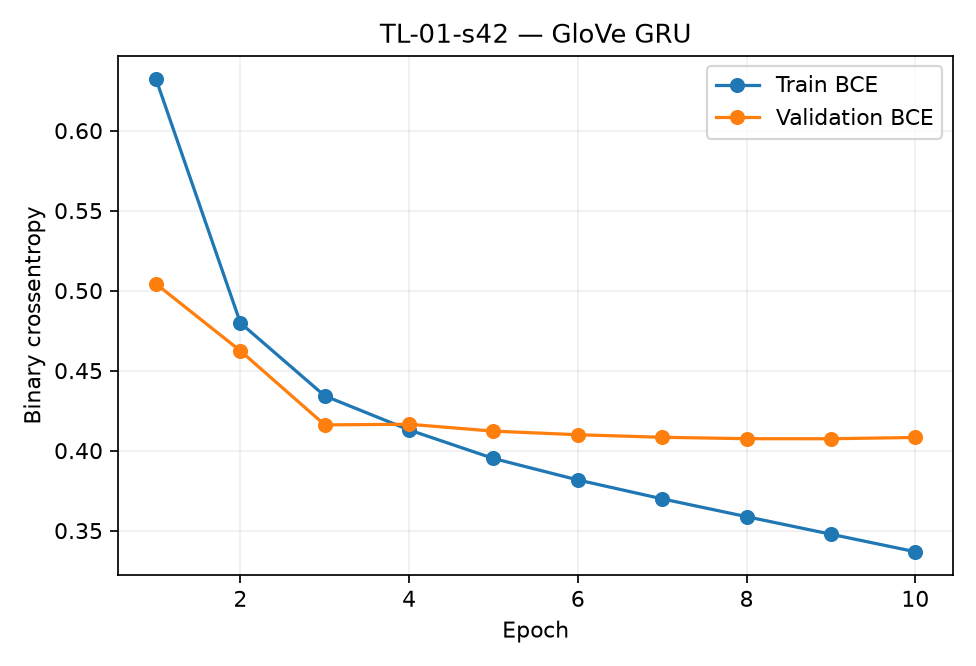

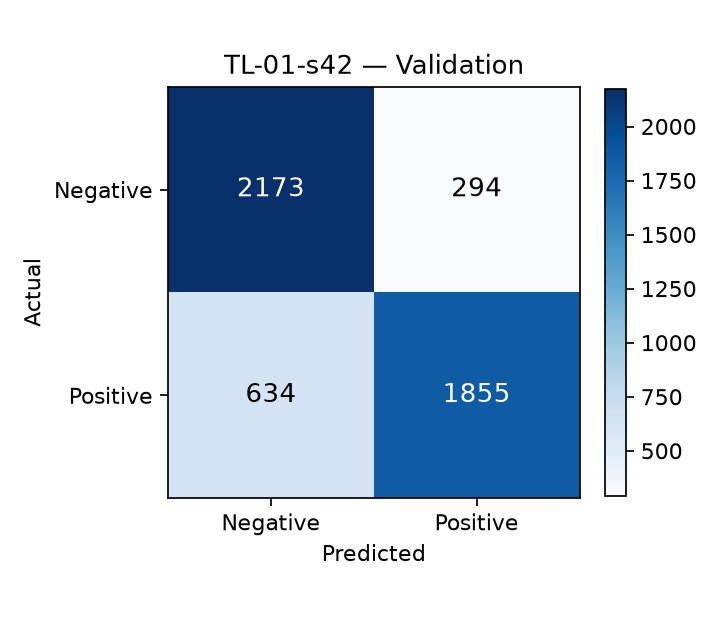

TL-02-s42 Loss curve and Validation confusion matrix


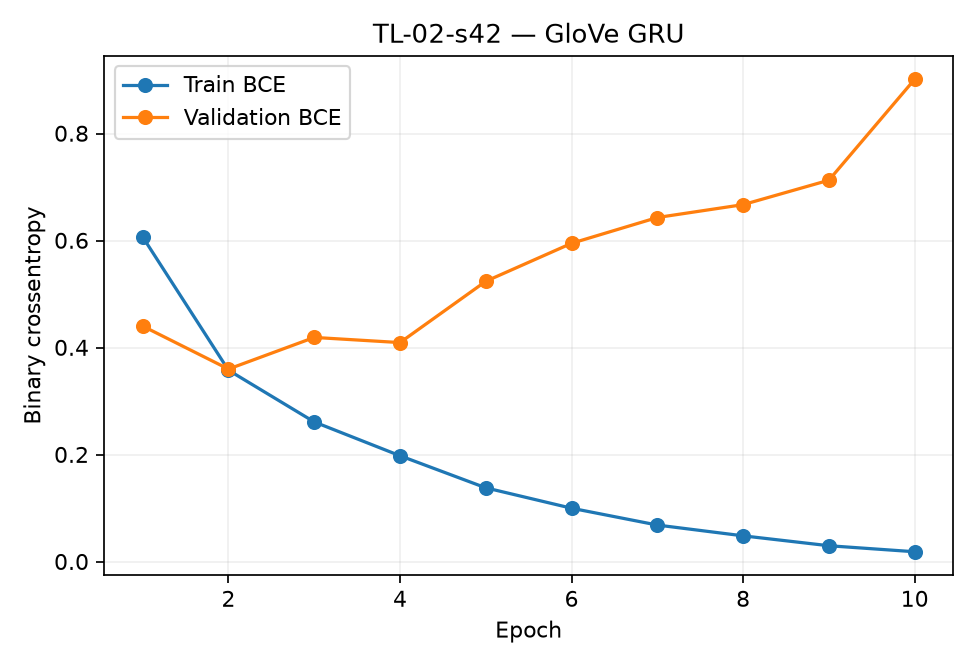

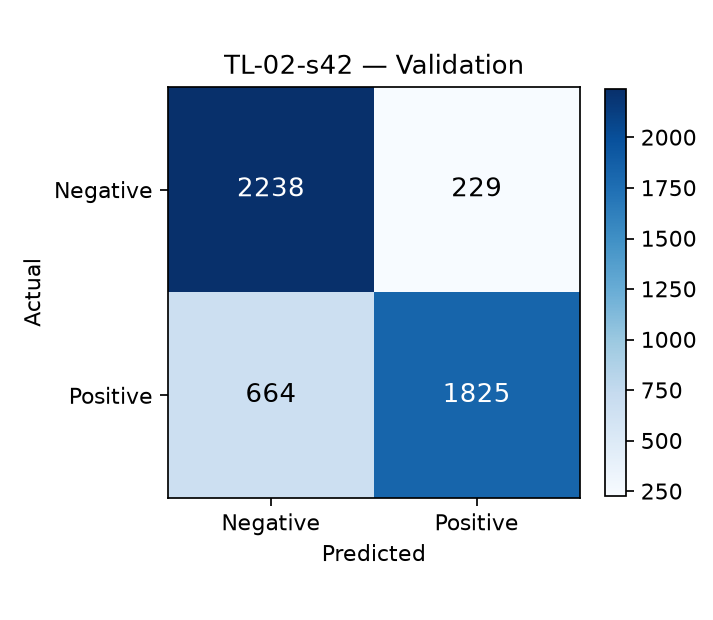

In [5]:
for rid in cfg['new_runs']:
    print(rid,'Loss curve and Validation confusion matrix')
    display(Image(filename=str(OPT/f'results/{rid}_loss.png'),width=550))
    display(Image(filename=str(OPT/f'results/{rid}_val_confusion_matrix.png'),width=370))


## 5. Random vs Frozen vs Fine-tuning 比較圖

比較的是同一份 Validation，不是事後重做 Test。原先 Gate E 的選模結論不因 TL-01/TL-02 改變。


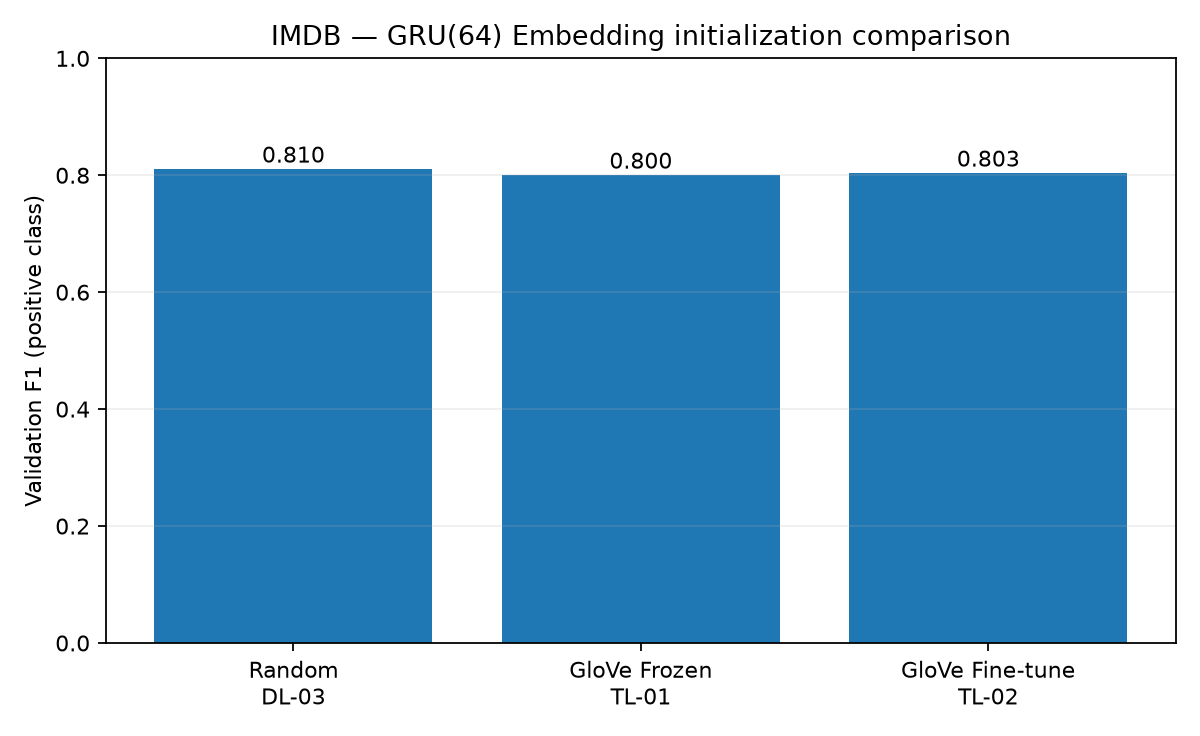

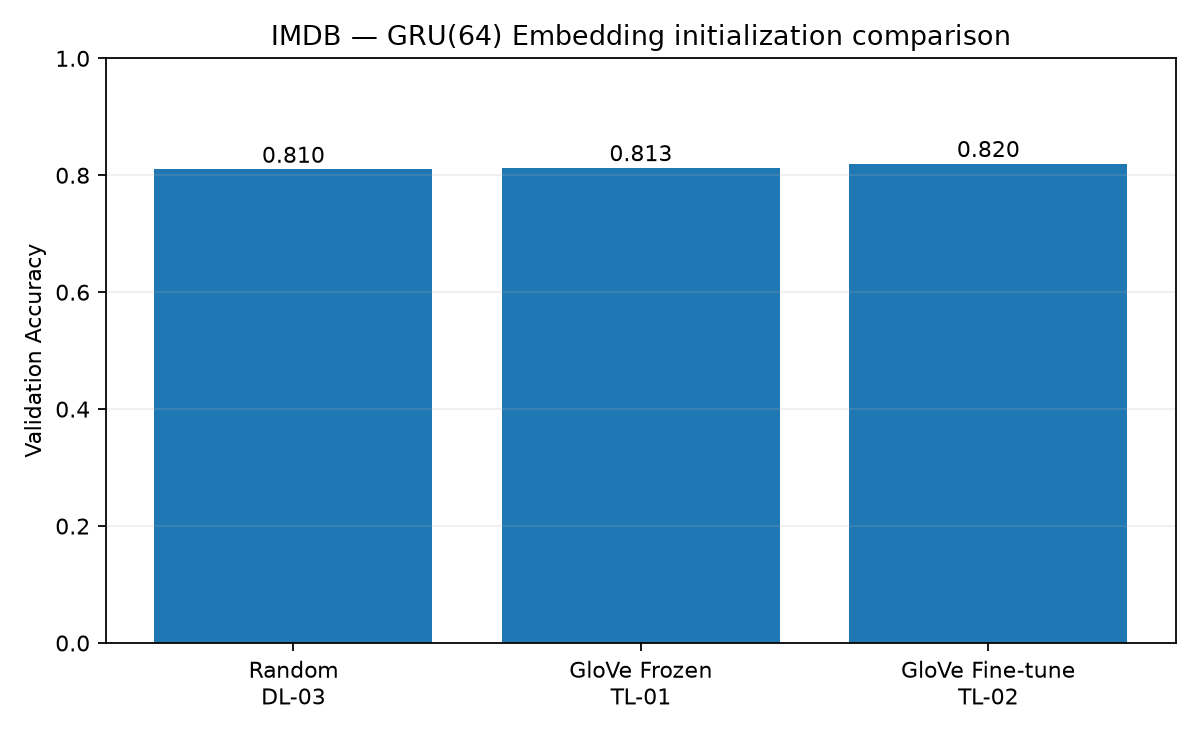

In [6]:
display(Image(filename=str(OPT/'results/glove_3way_validation_f1.png'),width=760))
display(Image(filename=str(OPT/'results/glove_3way_validation_accuracy.png'),width=760))


## 6. 模型及來源 SHA-256 稽核

來源壓縮檔、解壓詞向量、詞彙對齊矩陣、兩個新模型、逐筆 Validation 預測均保留雜湊；原始 14 組及 Gate E 成果保持不變。


In [7]:
original=frozen['source_artifacts_sha256']
assert all(file_hash(ROOT/p)==sha for p,sha in original.items())
for rid in cfg['new_runs']:
    r=json.loads((OPT/f'results/{rid}.json').read_text())
    assert file_hash(ROOT/r['predictions_path'])==r['predictions_sha256']
print('Original frozen artifacts confirmed:',len(original))
print('New GloVe runs:',cfg['new_runs'])
print('Official Test evaluations in optional GloVe: 0')


Original frozen artifacts confirmed: 26
New GloVe runs: ['TL-01-s42', 'TL-02-s42']
Official Test evaluations in optional GloVe: 0


## 7. RQ6 研究結論與限制

請依實測 Validation F1、Accuracy、Trainable Parameters、Loss 曲線比較隨機初始化、GloVe Frozen 與 Fine-tuning。預訓練的是 Embedding 詞向量，並不是預訓練了 GRU 分類器。

限制：單一 seed 42；標點附著的 token 會影響詞彙精確匹配；缺少多 seed 統計；此實驗晚於官方 Test，僅作事後選做研究。不可依此重新打開已鎖定的正式 Test 評估。
